In [1]:
import pathlib

from matplotlib.colors import ListedColormap
# import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import tensorflow as tf

from sklearn.model_selection import train_test_split

from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Conv2D, MaxPool2D, Dense, Flatten, Dropout

from PIL import Image

import datetime


2025-08-29 23:55:12.662067: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-08-29 23:55:12.690709: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-08-29 23:55:13.504249: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
DATA_BASE_DIR=pathlib.Path('../data_raw/fgvc-aircraft-2013b/data')

In [3]:
manufacturer_df= pd.read_csv(DATA_BASE_DIR/"images_manufacturer_train.txt",
            sep=" ",
            usecols=["image_id","manufacturer"],
            names=["image_id","manufacturer"],
            dtype={"image_id": str}, #to force the image_id to be a string,
        )

# Check integrity of the file

In [4]:
manufacturer_df['manufacturer'].value_counts(dropna=False)

manufacturer
Boeing         733
Airbus         434
Embraer        233
McDonnell      232
de             167
Canadair       134
Cessna         133
British        133
Douglas        133
Lockheed       102
Fokker         100
Beechcraft      67
Gulfstream      67
Saab            67
Dassault        67
ATR             66
Tupolev         66
Yakovlev        34
Antonov         34
Dornier         34
Panavia         34
Robin           33
Ilyushin        33
Eurofighter     33
Bombardier      33
Cirrus          33
Piper           33
Fairchild       33
Supermarine     33
Name: count, dtype: int64

In [5]:
manufacturer_df.isna().sum()

image_id        0
manufacturer    0
dtype: int64

In [6]:
for col in manufacturer_df.columns : 
    assert manufacturer_df[col].isna().sum() == 0 , "Missing value unexpected"

# Deal with N columns

## Make assumptions about number of spaces (here = 2) 
Naive method

In [7]:
manufacturer_df= pd.read_csv(DATA_BASE_DIR/"images_manufacturer_train.txt",
            sep=" ",
            names=["image_id","m1","m2"],
            usecols=["image_id","m1","m2"],
            dtype={"image_id": str} #to force the image_id to be a string 
        )
manufacturer_df["manufacturer"]= manufacturer_df["m1"]+ ' '+manufacturer_df["m2"]
manufacturer_df["manufacturer"].unique()

array([nan, 'British Aerospace', 'Lockheed Corporation',
       'Douglas Aircraft', 'McDonnell Douglas', 'de Havilland',
       'Lockheed Martin', 'Dassault Aviation', 'Bombardier Aerospace',
       'Gulfstream Aerospace', 'Cirrus Aircraft'], dtype=object)

In [8]:
!grep "T" ../data_raw/fgvc-aircraft-2013b/data/images_manufacturer_train.txt | head -3

0724121 ATR
0619697 ATR
2243949 ATR


In [9]:
!grep "T" ../data_raw/fgvc-aircraft-2013b/data/images_manufacturer_train.txt | wc -l

132


In [10]:
manufacturer_df= pd.read_csv(DATA_BASE_DIR/"images_manufacturer_train.txt",
            names=["all"],
        )
manufacturer_df["image_id"]=manufacturer_df["all"].apply(lambda x: x.split(' ')[0])
manufacturer_df["manufacturer"]=manufacturer_df["all"].apply(lambda x: ' '.join(x.split(' ')[1:]))
manufacturer_df["manufacturer"].unique()

array(['Boeing', 'Airbus', 'ATR', 'Antonov', 'British Aerospace',
       'Beechcraft', 'Lockheed Corporation', 'Douglas Aircraft Company',
       'Canadair', 'Cessna', 'McDonnell Douglas', 'de Havilland', 'Robin',
       'Dornier', 'Embraer', 'Eurofighter', 'Lockheed Martin',
       'Dassault Aviation', 'Fokker', 'Bombardier Aerospace',
       'Gulfstream Aerospace', 'Ilyushin', 'Fairchild', 'Piper',
       'Cirrus Aircraft', 'Saab', 'Supermarine', 'Panavia', 'Tupolev',
       'Yakovlev'], dtype=object)

In [11]:
manufacturer_df.head()

,all,image_id,manufacturer
0,1025794 Boeing,1025794,Boeing
1,1340192 Boeing,1340192,Boeing
2,0056978 Boeing,0056978,Boeing
3,0698580 Boeing,0698580,Boeing
4,0450014 Boeing,0450014,Boeing


In [12]:
manufacturer_df["path"]= manufacturer_df['image_id'].apply( lambda x: DATA_BASE_DIR/"images"/(x+'.jpg')) 

In [13]:
manufacturer_df.head()

,all,image_id,manufacturer,path
0,1025794 Boeing,1025794,Boeing,../data_raw/fgvc-aircraft-2013b/data/images/10...
1,1340192 Boeing,1340192,Boeing,../data_raw/fgvc-aircraft-2013b/data/images/13...
2,0056978 Boeing,0056978,Boeing,../data_raw/fgvc-aircraft-2013b/data/images/00...
3,0698580 Boeing,0698580,Boeing,../data_raw/fgvc-aircraft-2013b/data/images/06...
4,0450014 Boeing,0450014,Boeing,../data_raw/fgvc-aircraft-2013b/data/images/04...


In [14]:
def build_image_database(path,target):
    """    Build a pandas dataframe with target class and access path to images.

    Parameters:
        - path (Path): Path pattern to read csv file containing images information
        - target(str): The second column to extract from the file

    Return:
        A pandas dataframe,
    -------
    """
    #Load file
    _df= pd.read_csv(path,
            names=["all"],
        )
    #Recover data
    _df["image_id"]=_df["all"].apply(lambda x: x.split(' ')[0])
    _df[target]=_df["all"].apply(lambda x: ' '.join(x.split(' ')[1:]))
    _df[target].unique()

    #Create path
    _df["path"]= _df['image_id'].apply( lambda x: DATA_BASE_DIR/"images"/(x+'.jpg')) 
    
    return _df.drop(columns=["all"])

# Load manufacturer dataset

In [15]:
build_image_database(DATA_BASE_DIR/"images_manufacturer_train.txt","manufacturer").head(2)

,image_id,manufacturer,path
0,1025794,Boeing,../data_raw/fgvc-aircraft-2013b/data/images/10...
1,1340192,Boeing,../data_raw/fgvc-aircraft-2013b/data/images/13...


In [16]:
build_image_database(DATA_BASE_DIR/"images_family_train.txt","family").head(2)

,image_id,family,path
0,1025794,Boeing 707,../data_raw/fgvc-aircraft-2013b/data/images/10...
1,1340192,Boeing 707,../data_raw/fgvc-aircraft-2013b/data/images/13...


In [17]:
build_image_database(DATA_BASE_DIR/"images_variant_train.txt","variant").head(2)

,image_id,variant,path
0,1025794,707-320,../data_raw/fgvc-aircraft-2013b/data/images/10...
1,1340192,707-320,../data_raw/fgvc-aircraft-2013b/data/images/13...


In [18]:
manufacturer_df= build_image_database(DATA_BASE_DIR/"images_manufacturer_train.txt","manufacturer")

In [19]:
manufacturer_df.head(2)

,image_id,manufacturer,path
0,1025794,Boeing,../data_raw/fgvc-aircraft-2013b/data/images/10...
1,1340192,Boeing,../data_raw/fgvc-aircraft-2013b/data/images/13...


In [20]:
def show_image(df,row,target):
    """show the image in the ligne row and the associated target column

    Args:
        df (pandas.dataFrame): the dataframe of images
        row (int): the index of the row
        target (string): the column name of the associated label
    Return
    ------
    None
    """

    assert target in df.columns, f"Column {target} not found in dataframe"
    assert 'path' in df.columns, f"Column path doens't not exit in dataframe"
    _img = plt.imread(df.loc[row,'path'])
    print(df.loc[row,target])
    plt.imshow(_img)
    return

Boeing


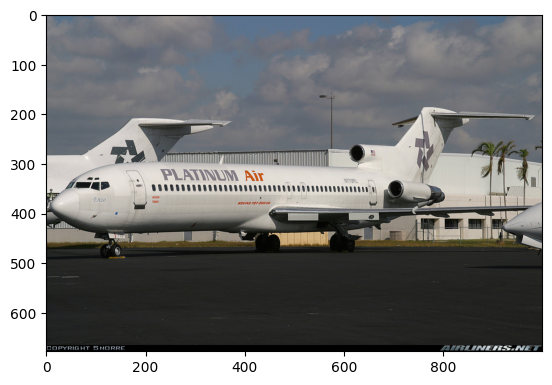

In [21]:
show_image(manufacturer_df,42,'manufacturer')

Boeing 707


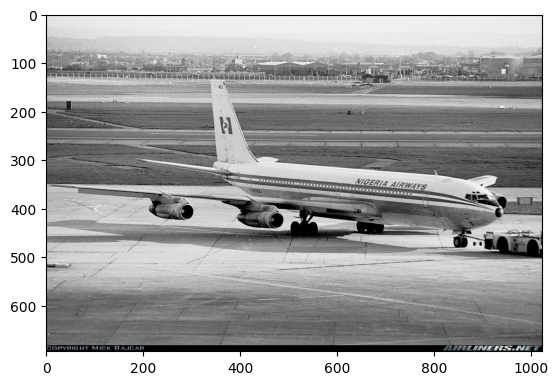

In [22]:
show_image(build_image_database(DATA_BASE_DIR/'images_family_train.txt','family'),24,'family')

In [23]:
manufacturer_df["image_shape"] =manufacturer_df["path"].apply(lambda p: plt.imread(p).shape)

In [24]:
manufacturer_df["image_shape"].apply(lambda x: x[0]).value_counts()

image_shape
695    627
812    310
678    271
679    186
694    107
      ... 
578      1
539      1
577      1
646      1
512      1
Name: count, Length: 404, dtype: int64

In [25]:
manufacturer_df["image_shape"].apply(lambda x: x[1]).value_counts()

image_shape
1024    1399
1200     618
1000     492
1600     145
1050     105
        ... 
1014       1
970        1
1430       1
1295       1
995        1
Name: count, Length: 73, dtype: int64

# Constante

In [26]:
IMAGE_WIDTH=128
IMAGE_HEIGHT=IMAGE_WIDTH
IMAGE_DEPTH = 3

In [27]:
def load_resize_image(path,height,width):
    """Load an image and resize it to the target size

    Parameters:
        - path (Path): path to the file to load and resize
        - height (int): the height of the final resized image
        - width(int): the width of the resized image 
    Return
    ------
    numpy.array containing resized image
    """

    return np.array(Image.open(path).resize((width,height)))

In [28]:
manufacturer_df.head(10).apply(lambda r: load_resize_image(r['path'],IMAGE_HEIGHT,IMAGE_WIDTH),axis=1)

0    [[[219, 219, 219], [219, 219, 219], [219, 219,...
1    [[[212, 212, 212], [220, 220, 220], [196, 196,...
2    [[[131, 167, 205], [134, 168, 206], [134, 168,...
3    [[[48, 63, 68], [49, 64, 68], [50, 64, 69], [4...
4    [[[116, 160, 231], [116, 160, 232], [116, 161,...
5    [[[202, 202, 202], [202, 202, 202], [201, 201,...
6    [[[37, 93, 129], [37, 94, 130], [38, 94, 129],...
7    [[[171, 171, 171], [172, 172, 172], [172, 172,...
8    [[[192, 190, 195], [192, 190, 195], [193, 191,...
9    [[[107, 140, 156], [109, 141, 158], [110, 144,...
dtype: object

In [29]:
manufacturer_df['resized_image'] = manufacturer_df.apply(lambda r: load_resize_image(r['path'],IMAGE_HEIGHT,IMAGE_WIDTH),axis=1)

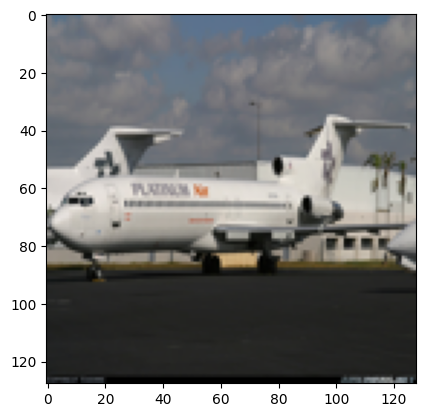

In [30]:
plt.imshow(manufacturer_df.loc[42,'resized_image'])

In [31]:
def build_classification_model(df: pd.DataFrame,target: str, images: str):
    """Build a tensorflow model using information from target and images columns in dataframes
    Parameters
    ----------
        - df (pandas.dataFrame): dataframe with target and images columns
        - target (str): column name for target variable
        - images (str): column name for images
    Returns
    ------
    tensorflow model built & compiled
    """
    
    #Compute number of classes for output layer
    nb_classes = df[target].nunique()
    
    # Computer images size for input layer
    size = df[images].iloc[0].shape
    
    # Building the model
    model = Sequential()
    model.add(tf.keras.Input(shape=size))
    model.add(Conv2D(filters=32, kernel_size=(5,5), activation='relu'))
    model.add(Conv2D(filters=32, kernel_size=(5,5), activation='relu'))
    model.add(MaxPool2D(pool_size=(2, 2)))
    model.add(Dropout(rate=0.25))
    model.add(Conv2D(filters=64, kernel_size=(3, 3), activation='relu'))
    model.add(Conv2D(filters=64, kernel_size=(3, 3), activation='relu'))
    model.add(MaxPool2D(pool_size=(2, 2)))
    model.add(Dropout(rate=0.25))
    model.add(Flatten())
    model.add(Dense(256, activation='relu'))
    model.add(Dropout(rate=0.5))
    model.add(Dense(nb_classes , activation='softmax'))

    #Compilation of the model
    model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy']) #output layer of nb_classes
    
    return model

In [32]:
build_classification_model(manufacturer_df,'manufacturer','resized_image')

<Sequential name=sequential, built=True>

In [33]:
# Compute the number of classes to shape the output layer
nb_classes = manufacturer_df.manufacturer.nunique()
nb_classes

30

In [36]:
#Building the model
model = Sequential()
model.add(Conv2D(filters=32, kernel_size=(5,5), activation='relu', input_shape=(IMAGE_WIDTH,IMAGE_HEIGHT,IMAGE_DEPTH)))
model.add(Conv2D(filters=32, kernel_size=(5,5), activation='relu'))
model.add(MaxPool2D(pool_size=(2, 2)))
model.add(Dropout(rate=0.25))
model.add(Conv2D(filters=64, kernel_size=(3, 3), activation='relu'))
model.add(Conv2D(filters=64, kernel_size=(3, 3), activation='relu'))
model.add(MaxPool2D(pool_size=(2, 2)))
model.add(Dropout(rate=0.25))
model.add(Flatten())
model.add(Dense(256, activation='relu'))
model.add(Dropout(rate=0.5))
model.add(Dense(nb_classes , activation='softmax'))

#Compilation of the model
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy']) #output layer of nb_classes


/home/adus229/projects/plane-classification/.venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [37]:
y=tf.keras.utils.to_categorical (manufacturer_df['manufacturer'].astype('category').cat.codes)

# Build train & Test set

In [38]:
def build_x_and_y(df: pd.DataFrame, target: str, images: str, stratify: str=None):
    """build x tensor and y tensor for model fitting.
    parameters
    ----------
    df(pd.DataFrame): dataframe 
    target(str): name of target column
    images (str): name of images column
        
    Returns
    -------
    
    x (numpy.array): tensor of x values
    y (numpy.array): tensor of y values
    """
    
    x= np.array(df[images].to_list())
    y=tf.keras.utils.to_categorical (df[target].astype('category').cat.codes)
    return x,y

In [39]:
X_train, X_test,y_train,y_test =  train_test_split(manufacturer_df[['resized_image',"manufacturer"]],y,test_size=0.2,stratify=manufacturer_df['manufacturer'])

In [40]:
assert X_train.shape[0]+X_test.shape[0]== manufacturer_df.shape[0]
assert y_train.shape[0]+y_test.shape[0]== y.shape[0]

In [41]:
X_train['manufacturer'].value_counts(normalize=True)

manufacturer
Boeing                      0.219723
Airbus                      0.130109
Embraer                     0.069741
McDonnell Douglas           0.069741
de Havilland                0.050244
Canadair                    0.040120
Cessna                      0.039745
Douglas Aircraft Company    0.039745
British Aerospace           0.039745
Fokker                      0.029996
Lockheed Corporation        0.020247
Beechcraft                  0.020247
Dassault Aviation           0.020247
Gulfstream Aerospace        0.020247
Saab                        0.020247
ATR                         0.019873
Tupolev                     0.019873
Robin                       0.010124
Piper                       0.010124
Dornier                     0.010124
Eurofighter                 0.010124
Antonov                     0.010124
Panavia                     0.010124
Fairchild                   0.010124
Lockheed Martin             0.010124
Yakovlev                    0.010124
Cirrus Aircraft          

In [42]:
X_test['manufacturer'].value_counts(normalize=True)

manufacturer
Boeing                      0.220390
Airbus                      0.130435
Embraer                     0.070465
McDonnell Douglas           0.068966
de Havilland                0.049475
Douglas Aircraft Company    0.040480
Canadair                    0.040480
Cessna                      0.040480
British Aerospace           0.040480
Fokker                      0.029985
Lockheed Corporation        0.020990
Beechcraft                  0.019490
Saab                        0.019490
Dassault Aviation           0.019490
Tupolev                     0.019490
ATR                         0.019490
Gulfstream Aerospace        0.019490
Lockheed Martin             0.010495
Ilyushin                    0.010495
Cirrus Aircraft             0.010495
Dornier                     0.010495
Panavia                     0.010495
Supermarine                 0.010495
Yakovlev                    0.010495
Antonov                     0.010495
Bombardier Aerospace        0.010495
Piper                    

# Train model 

In [43]:
%%time 
epochs = 5
history = model.fit(np.array(X_train['resized_image'].to_list()),y_train,batch_size = 32,epochs = epochs , validation_data = (np.array(X_test['resized_image'].to_list()),y_test))

Epoch 1/5
84/84 ━━━━━━━━━━━━━━━━━━━━ 14s 160ms/step - accuracy: 0.1901 - loss: 8.6181 - val_accuracy: 0.2204 - val_loss: 2.8937
Epoch 2/5
84/84 ━━━━━━━━━━━━━━━━━━━━ 14s 164ms/step - accuracy: 0.2103 - loss: 2.9027 - val_accuracy: 0.2219 - val_loss: 2.8490
Epoch 3/5
84/84 ━━━━━━━━━━━━━━━━━━━━ 14s 169ms/step - accuracy: 0.2325 - loss: 2.7085 - val_accuracy: 0.2204 - val_loss: 2.7361
Epoch 4/5
84/84 ━━━━━━━━━━━━━━━━━━━━ 14s 171ms/step - accuracy: 0.3037 - loss: 2.4569 - val_accuracy: 0.2204 - val_loss: 2.6820
Epoch 5/5
84/84 ━━━━━━━━━━━━━━━━━━━━ 15s 180ms/step - accuracy: 0.3405 - loss: 2.2090 - val_accuracy: 0.2654 - val_loss: 2.5939
CPU times: user 27min 50s, sys: 8.54 s, total: 27min 58s
Wall time: 1min 12s


In [44]:
#Load train & test dataset
train_df = build_image_database(DATA_BASE_DIR/'images_manufacturer_train.txt','manufacturer')
test_df = build_image_database(DATA_BASE_DIR/'images_manufacturer_test.txt','manufacturer')

train_df['resized_image'] = train_df.apply(lambda r: load_resize_image(r['path'],IMAGE_HEIGHT,IMAGE_WIDTH),axis=1)
test_df['resized_image'] = test_df.apply(lambda r: load_resize_image(r['path'],IMAGE_HEIGHT,IMAGE_WIDTH),axis=1)

#Build tensors for training & testing
X_train,y_train = build_x_and_y(train_df,'manufacturer','resized_image')
X_test,y_test = build_x_and_y(test_df,'manufacturer','resized_image')

model = build_classification_model(train_df,"manufacturer","resized_image")

In [45]:
# Load the TensorBoard notebook extension
%load_ext tensorboard

!rm -rf ./logs
log_dir = "logs/fit/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1)

In [47]:
%%time 
epochs = 5
history = model.fit(X_train,y_train,batch_size = 32,epochs = epochs , validation_data = (X_test,y_test),
                   callbacks=[tensorboard_callback]
                   )

Epoch 1/5
  1/105 [..............................] - ETA: 3:22 - loss: 61.7683 - accuracy: 0.0000e+00

2022-04-06 16:58:51.401772: I tensorflow/core/profiler/lib/profiler_session.cc:136] Profiler session initializing.
2022-04-06 16:58:51.402069: I tensorflow/core/profiler/lib/profiler_session.cc:155] Profiler session started.


  2/105 [..............................] - ETA: 1:24 - loss: 125.5768 - accuracy: 0.0000e+00

2022-04-06 16:58:52.207298: I tensorflow/core/profiler/lib/profiler_session.cc:71] Profiler session collecting data.
2022-04-06 16:58:52.211759: I tensorflow/core/profiler/lib/profiler_session.cc:172] Profiler session tear down.
2022-04-06 16:58:52.215092: I tensorflow/core/profiler/rpc/client/save_profile.cc:137] Creating directory: logs/fit/20220406-165844/train/plugins/profile/2022_04_06_16_58_52
2022-04-06 16:58:52.216032: I tensorflow/core/profiler/rpc/client/save_profile.cc:143] Dumped gzipped tool data for trace.json.gz to logs/fit/20220406-165844/train/plugins/profile/2022_04_06_16_58_52/rich-pc.trace.json.gz
2022-04-06 16:58:52.221350: I tensorflow/core/profiler/rpc/client/save_profile.cc:137] Creating directory: logs/fit/20220406-165844/train/plugins/profile/2022_04_06_16_58_52
2022-04-06 16:58:52.223805: I tensorflow/core/profiler/rpc/client/save_profile.cc:143] Dumped gzipped tool data for memory_profile.json.gz to logs/fit/20220406-165844/train/plugins/profile/2022_04_06_1

105/105 [==============================] - 90s 845ms/step - loss: 23.6739 - accuracy: 0.1637 - val_loss: 2.8461 - val_accuracy: 0.2199
Epoch 2/5
105/105 [==============================] - 90s 863ms/step - loss: 2.8310 - accuracy: 0.2143 - val_loss: 2.7308 - val_accuracy: 0.2208
Epoch 3/5
105/105 [==============================] - 89s 846ms/step - loss: 2.5245 - accuracy: 0.2667 - val_loss: 2.6859 - val_accuracy: 0.2478
Epoch 4/5
105/105 [==============================] - 93s 886ms/step - loss: 2.1923 - accuracy: 0.3507 - val_loss: 2.5187 - val_accuracy: 0.2718
Epoch 5/5
105/105 [==============================] - 90s 860ms/step - loss: 1.7263 - accuracy: 0.4739 - val_loss: 2.5655 - val_accuracy: 0.2670
CPU times: user 28min 54s, sys: 12min 12s, total: 41min 7s
Wall time: 7min 35s


In [46]:
%tensorboard  --logdir  logs/fit 

In [48]:
import tensorflow as tf; print(tf.config.list_physical_devices('GPU'))


[]


In [49]:
model.predict(X_test[10:11])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step


array([[9.09769482e-10, 1.94580880e-05, 2.97313673e-16, 5.61037213e-02,
        8.81816050e-06, 8.83834728e-10, 6.90795132e-05, 1.86444566e-12,
        1.14434215e-07, 1.51487823e-17, 6.10953959e-16, 1.35875394e-10,
        7.58097452e-15, 1.53760976e-10, 1.45048448e-12, 2.27791633e-10,
        2.91904553e-06, 8.40418279e-01, 1.44697393e-10, 5.59332615e-11,
        9.85235438e-17, 1.05363133e-13, 6.00449326e-08, 8.77451143e-08,
        7.94900240e-16, 1.23612811e-19, 3.54585028e-09, 1.96378513e-09,
        1.03377499e-01, 4.15080782e-11]], dtype=float32)

Boeing


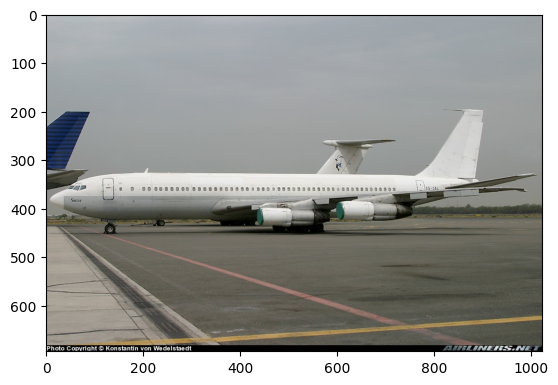

In [50]:
show_image(test_df,10,'manufacturer')

In [51]:
np.argmax(model.predict(X_test[10:20]),axis=1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step


array([17, 17,  3, 28,  3, 17,  3,  3, 28, 17])

In [52]:
def classify_images(images,model,classes_names=None)->int:
    """Classify images through a tensorflow model.
    
    Parameters:
    -----------
    
    images(np.array): set of images to classify
    model (tensorflow.keras.Model): tensorflow/keras model
    
    Returns
    -------
    predicted classes 
    
    """
    
    results = model.predict(images)
    classes = np.argmax(results,axis=1)
    if classes_names is not None:
        classes = np.array(classes_names[classes])
    return classes

NameError: name 'sns' is not defined

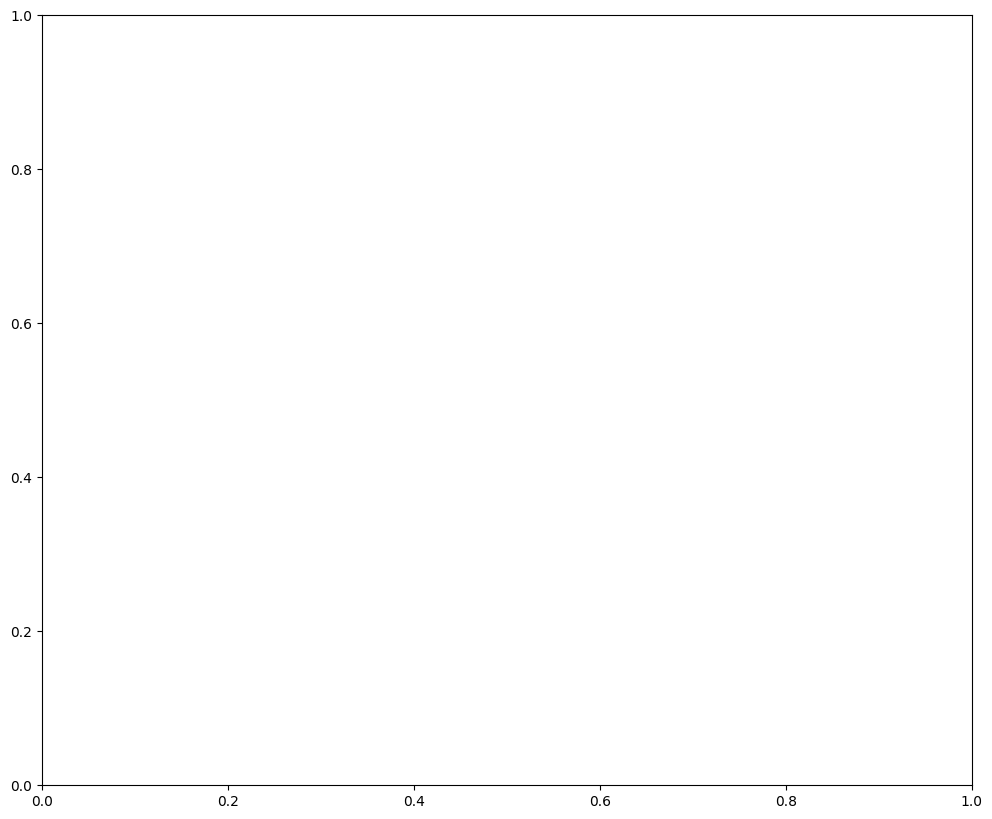

In [53]:
fig, ax = plt.subplots(figsize=(12,10))
sns.heatmap(pd.crosstab(np.argmax(y_test,axis=1),classify_images(X_test,model), normalize='index'), cmap='vlag', ax=ax)

NameError: name 'sns' is not defined

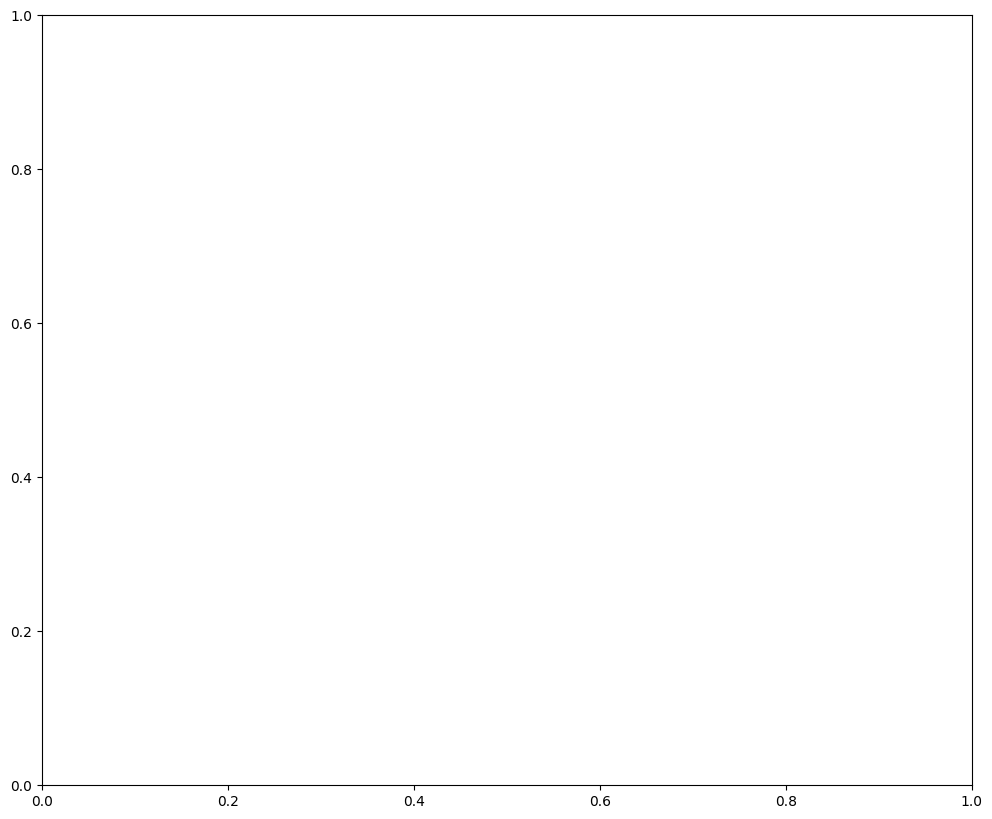

In [54]:
fig, ax = plt.subplots(figsize=(12,10))
sns.heatmap(pd.crosstab(test_df['manufacturer'],classify_images(X_test,model,test_df['manufacturer'].astype('category').cat.categories), normalize='index'), cmap='vlag', ax=ax)

<AxesSubplot:xlabel='col_0', ylabel='row_0'>

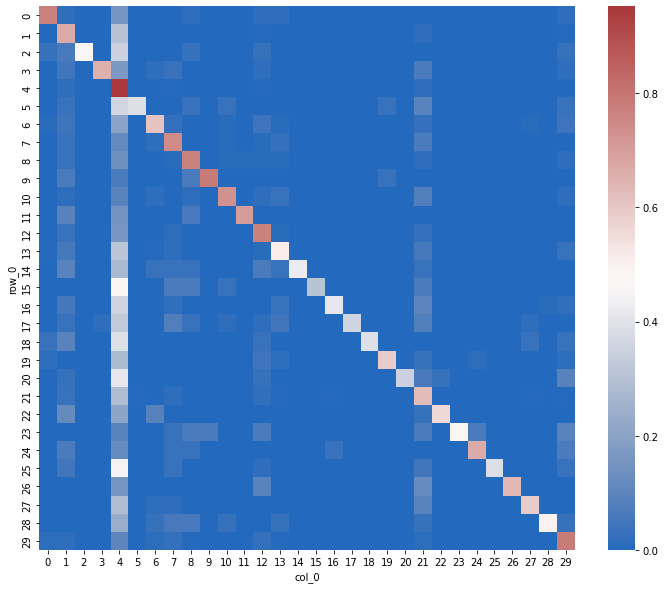

In [58]:
fig, ax = plt.subplots(figsize=(12,10))
sns.heatmap(pd.crosstab(np.argmax(y_train,axis=1),classify_images(X_train,model), normalize='index'), cmap='vlag', ax=ax)

NameError: name 'sns' is not defined

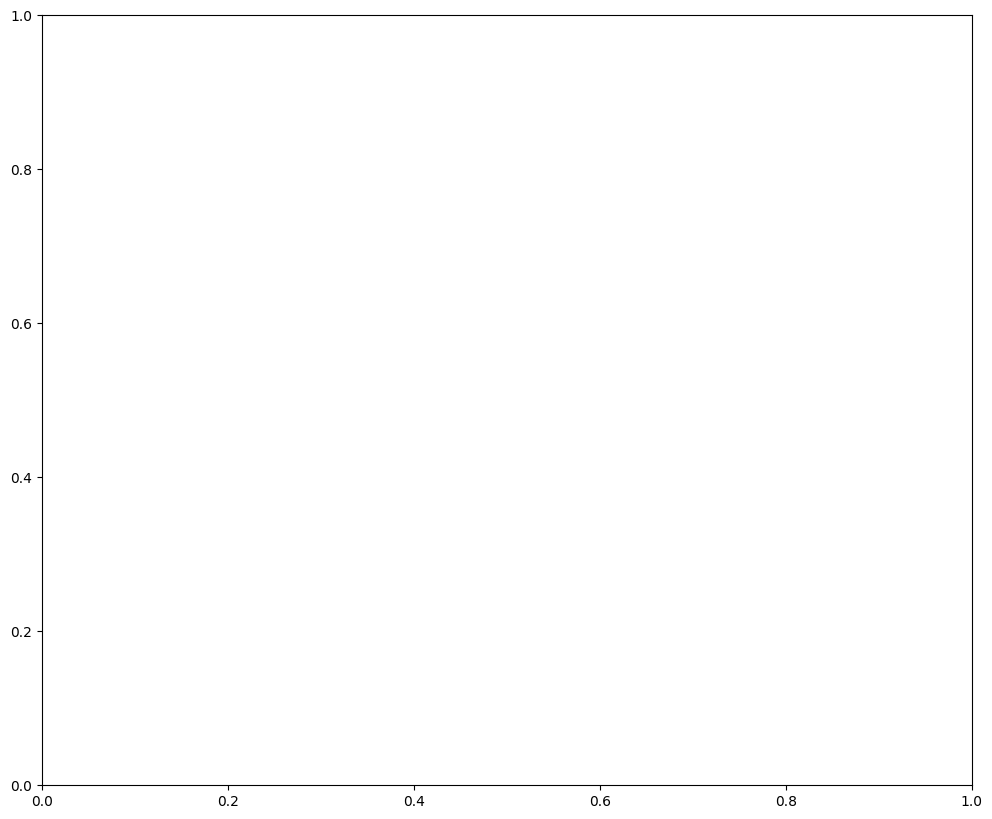

In [55]:
fig, ax = plt.subplots(figsize=(12,10))
sns.heatmap(pd.crosstab(train_df['manufacturer'],classify_images(X_train,model,train_df['manufacturer'].astype('category').cat.categories), normalize='index'), cmap='vlag', ax=ax)

In [60]:
def save_model(model, basename):
  """Save tf/Keras model.

  Model file is named model + timestamp.

  Parameters
  ----------
  model (tf/Keras model): model to be saved
  basename: location to save model file
  """
  model.save('{}_{}.h5'.format(basename, datetime.datetime.now().strftime('%Y-%m-%d_%H-%M-%S')))
  return

In [63]:
model.save("../model/my_model.h5")

In [64]:
reloaded_model = load_model('../model/my_model.h5')

In [65]:
np.argmax(reloaded_model.predict(X_test[10:20]), axis=1)

array([ 4,  4,  4,  0,  4,  4,  4,  4, 29,  4])